# Appendix B | Worked solutions

*Matrix Calculus and Optimization*

Gradients add along shared paths, token means require token weights, and nonlinear optimizer operations must be applied in the correct order. The examples check derivatives independently and separate adaptive updates from weight decay.

Eight exercises progress from tracing small calculations to diagnosing implementation errors. These are controlled numerical examples, not performance or model-quality benchmarks.

## Setup

Run all cells in order from anywhere inside the companion repository. The written PDF contains every problem, explanation, and plot; the notebook PDF adds the code and saved outputs. NumPy and Matplotlib are required; Appendix C also uses PyTorch. No downloads, credentials, GPU, or trained checkpoint are needed.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "examples/ch04_attention/attention.py").exists())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcdefaults()
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})


## 1. Follow a scalar derivative

**Problem.** For $z=\theta x$, $L=(z-y)^2/2$, take $\theta=1$, $x=4$, $y=6$. Find loss and derivative, and the direction of a small descent step.

**Solution.** The prediction is 4, the residual is $-2$, and the loss is 2. The chain rule gives $(z-y)x=(-2)(4)=-8$. Descent subtracts this negative gradient, so it increases the parameter. At learning rate 0.01, the new parameter is 1.08, the prediction is 4.32, and the loss is 1.4112. A very large step could overshoot; the derivative describes a local direction.

Loss: 2.0 Gradient: -8.0
New parameter: 1.08 New loss: 1.4111999999999996


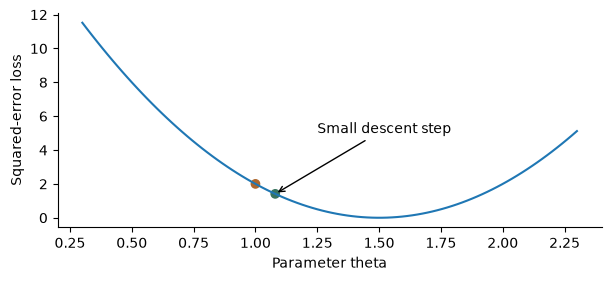

In [2]:
theta, x, target = 1., 4., 6.
loss = lambda p: .5 * (p*x-target)**2
grad = (theta*x-target)*x
updated = theta-.01*grad
assert loss(theta)==2 and grad==-8
assert loss(updated)<loss(theta)
print("Loss:",loss(theta),"Gradient:",grad)
print("New parameter:",updated,"New loss:",loss(updated))
grid=np.linspace(.3,2.3,100)
fig,ax=plt.subplots(figsize=(6,2.7),layout="constrained")
ax.plot(grid,loss(grid),label="Loss")
ax.scatter([theta,updated],[loss(theta),loss(updated)],color=["#ad672d","#39745e"])
ax.set(xlabel="Parameter theta",ylabel="Squared-error loss")
ax.annotate("Small descent step",xy=(updated,loss(updated)),xytext=(1.25,5),
            arrowprops={"arrowstyle":"->"});plt.show()

## 2. Differentiate cross-entropy

**Problem.** For logits $(0,\log3)$ and the first class as target, compute probabilities, loss, gradient, and the sum of gradient entries.

**Solution.** The exponentials are 1 and 3, so probabilities are $(1/4,3/4)$. The correct-class loss is $-\log(1/4)=\log4$. Subtracting target $(1,0)$ gives gradient $(-3/4,3/4)$. Its entries sum to zero: moving both logits by one common constant leaves their differences, probabilities, and loss unchanged. A descent step raises the correct logit and lowers the other.

In [3]:
z=np.array([0.,np.log(3.)]);p=np.exp(z-z.max());p/=p.sum()
grad=p-np.array([1.,0.])
loss=np.log(np.exp(z-z.max()).sum())-(z[0]-z.max())
np.testing.assert_allclose(p,[.25,.75])
np.testing.assert_allclose(grad,[-.75,.75]);assert grad.sum()==0
np.testing.assert_allclose(loss,np.log(4))
print("Probabilities:",p,"Loss:",loss,"Gradient:",grad)

Probabilities: [0.25 0.75] Loss: 1.3862943611198906 Gradient: [-0.75  0.75]


## 3. Weight by valid tokens

**Problem.** Two pieces contain two and five valid labels, with mean gradients 4 and $-3$. Find the combined mean. Does splitting the second piece change it when sums are used?

**Solution.** The loss-gradient sums are $2(4)=8$ and $5(-3)=-15$. Divide their total $-7$ by seven valid labels to obtain $-1$. Averaging the two means gives 0.5, which incorrectly gives equal weight to unequal token counts. Splitting a piece preserves its total gradient sum and token count, so it preserves the combined result. This argument assumes the same parameters and per-token forward computations.

In [4]:
counts=np.array([2,5]);means=np.array([4.,-3.])
combined=(counts*means).sum()/counts.sum()
# These five token gradients have mean -3 but unequal values.
second=np.array([-5.,-4.,-3.,-2.,-1.])
split_sum=8+second[:2].sum()+second[2:].sum()
assert combined==-1 and split_sum/7==combined
print("Token-weighted mean:",combined)
print("Incorrect mean of piece means:",means.mean())
print("After repartition:",split_sum/7)

Token-weighted mean: -1.0
Incorrect mean of piece means: 0.5
After repartition: -1.0


## 4. Clip once and separate decay

**Problem.** Two tensors have gradients $(6,8)$ and $(0,0)$. Clip their global norm to 5. Separately, evaluate AdamW for old parameter 2, corrected moments 1 and 4, learning rate 0.1, decay 0.2, negligible epsilon.

**Solution.** The concatenated gradient has norm 10, so all entries receive multiplier $5/10$. The tensors become $(3,4)$ and $(0,0)$. In the separate AdamW calculation, decay contributes $-0.1(0.2)(2)=-0.04$. The adaptive step contributes $-0.1(1)/\sqrt4=-0.05$. The new parameter is $2-0.04-0.05=1.91$. Decay is applied to the old weight outside the adaptive division.

In [5]:
g=np.array([6.,8.,0.,0.]);clipped=g*min(1.,5/np.linalg.norm(g))
np.testing.assert_allclose(clipped,[3,4,0,0])
decay=-.1*.2*2;adaptive=-.1*1/np.sqrt(4)
new=2+decay+adaptive
np.testing.assert_allclose(new,1.91)
print("Clipped gradient:",clipped,"Norm:",np.linalg.norm(clipped))
print("Decay change:",decay,"Adaptive change:",adaptive,"New value:",new)

Clipped gradient: [3. 4. 0. 0.] Norm: 5.0
Decay change: -0.04000000000000001 Adaptive change: -0.05 New value: 1.91


## 5. Check every matrix derivative

**Problem.** Use $X=((2,1),(1,3))$, $W=((1,0,-1),(2,1,0))$, and $G=((1,0,-1),(0,2,1))$. For $L=\sum G_{ij}(XW)_{ij}$, check all weight and input derivatives by float64 central differences at $10^{-6}$. Why hold $G$ fixed?

**Solution.** The fixed array $G$ defines this scalar probe loss. Differentiating $G$ as well would define a different function. The analytic derivatives are $X^\top G=((2,2,-1),(1,6,2))$ and $GW^\top=((2,2),(-1,2))$. Each central difference perturbs one coordinate, evaluates the same scalar loss twice, and divides by twice the perturbation. This loss is linear in each array when the other is fixed, so central differences have no truncation error in exact arithmetic; floating-point cancellation still remains. A nonlinear example illustrates why the perturbation cannot be arbitrarily tiny.

Weight derivatives:
 [[ 2.  2. -1.]
 [ 1.  6.  2.]] 
Input derivatives:
 [[ 2.  2.]
 [-1.  2.]]


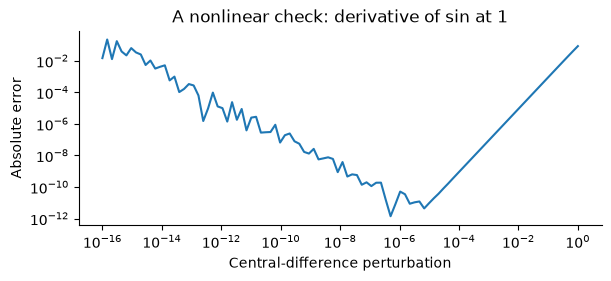

In [6]:
X=np.array([[2.,1.],[1.,3.]])
W=np.array([[1.,0.,-1.],[2.,1.,0.]])
G=np.array([[1.,0.,-1.],[0.,2.,1.]])
def central_difference(fn, array, delta=1e-6):
    result=np.empty_like(array)
    for index in np.ndindex(array.shape):
        plus=array.copy();minus=array.copy()
        plus[index]+=delta;minus[index]-=delta
        result[index]=(fn(plus)-fn(minus))/(2*delta)
    return result
dW=central_difference(lambda w: np.sum(G*(X@w)),W)
dX=central_difference(lambda x: np.sum(G*(x@W)),X)
np.testing.assert_allclose(dW,X.T@G,atol=1e-8,rtol=1e-8)
np.testing.assert_allclose(dX,G@W.T,atol=1e-8,rtol=1e-8)
print("Weight derivatives:\n",dW,"\nInput derivatives:\n",dX)
deltas=np.logspace(-16,0,100)
errors=np.abs((np.sin(1+deltas)-np.sin(1-deltas))/(2*deltas)-np.cos(1))
fig,ax=plt.subplots(figsize=(6,2.7),layout="constrained")
ax.loglog(deltas,np.maximum(errors,1e-17))
ax.set(xlabel="Central-difference perturbation",ylabel="Absolute error",
       title="A nonlinear check: derivative of sin at 1")
plt.show()

## 6. Add shared contributions

**Problem.** For $Y=XW+b$ with the same $G$, compute the shared-bias gradient. A second branch contributes ones to the input gradient. Find the total and explain why it is a sum.

**Solution.** The shared bias affects both rows, so its gradient is their sum: $(1,2,0)$. The first branch gives input gradient $((2,2),(-1,2))$; adding the second gives $((3,3),(0,3))$. Both paths affect the same scalar loss, and the chain rule adds their effects. Averaging would incorrectly halve the derivative unless the loss itself included that averaging factor.

In [7]:
db=G.sum(axis=0)
total_dX=G@W.T+np.ones_like(X)
np.testing.assert_array_equal(db,[1,2,0])
np.testing.assert_array_equal(total_dX,[[3,3],[0,3]])
# Independent probe loss includes both branches explicitly.
probe=lambda x: np.sum(G*(x@W))+x.sum()
np.testing.assert_allclose(central_difference(probe,X),total_dX,
                           atol=1e-8,rtol=1e-8)
print("Bias gradient:",db,"\nTotal input gradient:\n",total_dX)

Bias gradient: [1. 2. 0.] 
Total input gradient:
 [[3. 3.]
 [0. 3.]]


## 7. Order accumulation and clipping

**Problem.** Equal-size pieces have scalar mean gradients 10 and $-6$. Clip at 5. Compare clipping before and after accumulation; repeat with scale 128, and test clipping before unscaling.

**Solution.** The combined mean is $(10-6)/2=2$ and remains 2 after clipping. Clipping each piece first gives $(5-5)/2=0$. With scaled piece means 1280 and $-768$, sum to 512, unscale to 4, divide by two, then clip to obtain 2. Equivalently, form the scaled mean 256, unscale it, then clip. Clipping that scaled mean at the unscaled threshold 5 and dividing by 128 instead gives 0.0390625, which is wrong. For loss sums with unequal valid counts, normalize by the total count rather than the number of pieces.

In [8]:
means=np.array([10.,-6.]);threshold=5.;scale=128.
correct=np.clip(means.mean(),-threshold,threshold)
early=np.clip(means,-threshold,threshold).mean()
scaled=means*scale
recovered=np.clip((scaled.sum()/scale)/2,-threshold,threshold)
wrong=np.clip(scaled.mean(),-threshold,threshold)/scale
assert correct==recovered==2 and early==0
assert wrong==.0390625
print("Clip final mean:",correct,"Clip pieces first:",early)
print("Unscale, normalize, clip:",recovered)
print("Clip before unscaling:",wrong)

Clip final mean: 2.0 Clip pieces first: 0.0
Unscale, normalize, clip: 2.0
Clip before unscaling: 0.0390625


## 8. Trace the first AdamW step

**Problem.** Start at parameter 2, zero moments, beta values 0.9 and 0.99, learning rate 0.1 and decay 0.2. Compute the first step for gradients 3 and $-3$, neglecting epsilon.

**Solution.** For $g=3$, the moments are $m=0.1(3)=0.3$ and $v=0.01(9)=0.09$. Dividing by $1-0.9$ and $1-0.99$ gives corrected moments 3 and 9. Decay contributes $-0.04$ and the adaptive term contributes $-0.1$, giving 1.86. For $g=-3$, the first moment and corrected first moment change signs; the second moments remain positive. Decay still contributes $-0.04$, while the adaptive term is $+0.1$, giving 2.06. On this first scalar step with negligible epsilon, the adaptive magnitude depends on the gradient sign, not its nonzero magnitude; this is not ordinary gradient descent.

In [9]:
for g,expected in [(3.,1.86),(-3.,2.06)]:
    m=(1-.9)*g;v=(1-.99)*g*g
    mhat=m/(1-.9);vhat=v/(1-.99)
    decay=-.1*.2*2
    adaptive=-.1*mhat/np.sqrt(vhat)
    updated=2+decay+adaptive
    np.testing.assert_allclose([mhat,vhat,updated],[g,9,expected])
    print(f"g={g:+.0f}: m={m:+.2f}, v={v:.2f}, "
          f"mhat={mhat:+.0f}, vhat={vhat:.0f}")
    print(f"  decay={decay:+.2f}, adaptive={adaptive:+.2f}, theta={updated:.2f}")

g=+3: m=+0.30, v=0.09, mhat=+3, vhat=9
  decay=-0.04, adaptive=-0.10, theta=1.86
g=-3: m=-0.30, v=0.09, mhat=-3, vhat=9
  decay=-0.04, adaptive=+0.10, theta=2.06
